# Coffee Shop Sales：基础清洗与 EDA

按顺序阅读和运行，每一步都在本 Notebook 内输出表格或图表。原始 CSV 不修改，清洗后的数据保存在变量 `df` 中。最后把结果转成符合课程要求的研究方向和看板方案。

**先说明数据口径：**每行记录一个门店、一个时间点、一个商品及其数量。虽然字段叫 `transaction_id`，但本表没有小票号、顾客 ID，多个商品可能在相同时间出现。因此下文称“销售记录”，不把行数当作顾客数、完整订单数，也不把单行均额称为客单价。

**数据来源核查：**本地文件的字段、规模和内容与 Maven Roasters 数据相符。Maven 官方将它描述为纽约三个地点的**虚构咖啡连锁业务**，应按模拟业务数据使用，而非真实门店证据。原始来源：[Maven Analytics](https://mavenanalytics.io/data-playground/coffee-shop-sales)。同源 Kaggle 参考：[Coffee Shop Sales](https://www.kaggle.com/datasets/ahmedabbas757/coffee-sales)。本地 CSV 没有下载来源元数据，最终 README 应填写你实际下载的 Kaggle 数据集页面；不能仅凭内容相似断定上传者和版本。

图表用于探索，最后建议的正式看板只保留最多三个 KPI、两个图表。这里先不开发或部署 Streamlit。


## 1. 读取原始数据，先看它长什么样

依赖只有 Pandas、NumPy、Matplotlib。运行时请让 Notebook 的工作目录位于 Coffee 文件夹。所有清洗均可从原始 CSV 重新运行，不依赖前一次手工修改。


In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import StrMethodFormatter

from os import environ

def find_assignment_dir(filename):
    """Locate this assignment from its folder, ml4biz, or a child folder."""
    candidates = []
    if environ.get("ASSIGNMENT4_DIR"):
        candidates.append(Path(environ["ASSIGNMENT4_DIR"]).expanduser())
    for base in (Path.cwd(), *Path.cwd().parents):
        candidates.extend((base, base / "assignment4", base / "ml4biz" / "assignment4"))
    for candidate in candidates:
        if (candidate / filename).is_file() and (candidate / "app.py").is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Cannot find {filename}. Run this notebook from assignment4 or ml4biz, "
        "or set ASSIGNMENT4_DIR to the assignment4 folder."
    )

PROJECT_DIR = find_assignment_dir("Coffee Shop Sales.csv")
DATA_PATH = PROJECT_DIR / "Coffee Shop Sales.csv"
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 2)
pd.set_option('display.width', 160)
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plot_font = next((f for f in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams.update({'font.family': plot_font, 'axes.unicode_minus': False,
                     'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlepad': 12,
                     'axes.prop_cycle': plt.cycler(color=['#78533C', '#398074', '#C98C45'])})
print(f'原始数据：{raw.shape[0]:,} 行 × {raw.shape[1]} 列')
print(f'文件大小：{DATA_PATH.stat().st_size / 1_000_000:.2f} MB，低于课程约 25 MB 的要求，无需抽样。')
display(raw.head(8))


原始数据：149,116 行 × 11 列
文件大小：13.33 MB，低于课程约 25 MB 的要求，无需抽样。


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,1/1/23,7:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,1/1/23,7:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,1/1/23,7:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,1/1/23,7:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,1/1/23,7:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
5,6,1/1/23,7:22:41,1,5,Lower Manhattan,77,3.0,Bakery,Scone,Oatmeal Scone
6,7,1/1/23,7:25:49,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
7,8,1/1/23,7:33:34,2,5,Lower Manhattan,28,2.0,Coffee,Gourmet brewed coffee,Columbian Medium Roast Sm


In [2]:
meanings = {
    'transaction_id': '销售记录 ID；不能识别顾客或完整购物篮',
    'transaction_date': '原始日期字符串，月/日/两位年份',
    'transaction_time': '原始时间字符串，时:分:秒；未提供时区',
    'transaction_qty': '该行商品售出数量',
    'store_id': '门店标识，数值编码不是连续测量值',
    'store_location': '门店位置名称',
    'product_id': '商品标识，数值编码不是连续测量值',
    'unit_price': '该行商品单价；按纽约业务场景采用 USD 口径，CSV 本身无币种列',
    'product_category': '商品大类',
    'product_type': '商品类型',
    'product_detail': '具体商品名称，部分带规格后缀'
}
schema = pd.DataFrame({
    '字段': raw.columns,
    '原始类型': raw.dtypes.astype(str).values,
    '非空数': raw.notna().sum().values,
    '不同取值数': raw.nunique().values,
    '含义': [meanings[c] for c in raw.columns]
})
display(schema)


,字段,原始类型,非空数,不同取值数,含义
0,transaction_id,int64,149116,149116,销售记录 ID；不能识别顾客或完整购物篮
1,transaction_date,str,149116,181,原始日期字符串，月/日/两位年份
2,transaction_time,str,149116,25762,原始时间字符串，时:分:秒；未提供时区
3,transaction_qty,int64,149116,6,该行商品售出数量
4,store_id,int64,149116,3,门店标识，数值编码不是连续测量值
5,store_location,str,149116,3,门店位置名称
6,product_id,int64,149116,80,商品标识，数值编码不是连续测量值
7,unit_price,float64,149116,41,该行商品单价；按纽约业务场景采用 USD 口径，CSV 本身无币种列
8,product_category,str,149116,9,商品大类
9,product_type,str,149116,29,商品类型


## 2. 清洗前检查：缺失、空白、重复和字符串空格

区分三种重复：整行完全重复、交易 ID 重复、仅业务字段相同但 ID 不同。第三种只能作为检查线索，不能自动删除。**相同门店和时间不代表同一订单**，也不据此合并购物篮。


In [3]:
text_cols = ['store_location', 'product_category', 'product_type', 'product_detail']
quality = pd.DataFrame(index=raw.columns)
quality['缺失数'] = raw.isna().sum()
quality['缺失率_%'] = raw.isna().mean().mul(100)
quality['纯空白字符串数'] = [int(raw[c].astype('string').str.strip().eq('').sum()) for c in raw.columns]
quality['首尾空格数'] = [int(raw[c].ne(raw[c].astype('string').str.strip()).sum()) if c in text_cols else 0 for c in raw.columns]
display(quality.reset_index(names='字段'))
business_cols = raw.columns.drop('transaction_id').tolist()
duplicate_check = pd.DataFrame({
    '检查': ['整行完全重复（多余行数）', '重复 transaction_id（多余行数）',
             '除 ID 外业务字段相同（多余行数）', '同门店同日期同时间的记录（所有涉及行）'],
    '数量': [int(raw.duplicated().sum()), int(raw.transaction_id.duplicated().sum()),
             int(raw.duplicated(business_cols).sum()),
             int(raw.duplicated(['store_id', 'transaction_date', 'transaction_time'], keep=False).sum())],
    '处理': ['本数据为 0', '本数据为 0', '保留，无法确认是错误', '保留，不能用时间戳推断订单']
})
display(duplicate_check)
print('需要去除首尾空格的商品名称示例：')
display(raw.loc[raw.product_detail.ne(raw.product_detail.str.strip()), ['product_id', 'product_detail']].drop_duplicates().assign(原值可见表示=lambda x: x.product_detail.map(repr)))
print('业务字段相同但 ID 不同的示例（保留）：')
display(raw.loc[raw.duplicated(business_cols, keep=False)].head(6))


,字段,缺失数,缺失率_%,纯空白字符串数,首尾空格数
0,transaction_id,0,0.0,0,0
1,transaction_date,0,0.0,0,0
2,transaction_time,0,0.0,0,0
3,transaction_qty,0,0.0,0,0
4,store_id,0,0.0,0,0
5,store_location,0,0.0,0,0
6,product_id,0,0.0,0,0
7,unit_price,0,0.0,0,0
8,product_category,0,0.0,0,0
9,product_type,0,0.0,0,0


,检查,数量,处理
0,整行完全重复（多余行数）,0,本数据为 0
1,重复 transaction_id（多余行数）,0,本数据为 0
2,除 ID 外业务字段相同（多余行数）,398,保留，无法确认是错误
3,同门店同日期同时间的记录（所有涉及行）,61586,保留，不能用时间戳推断订单


需要去除首尾空格的商品名称示例：


,product_id,product_detail,原值可见表示
42,78,Scottish Cream Scone,'Scottish Cream Scone '


业务字段相同但 ID 不同的示例（保留）：


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
3255,3285,1/7/23,7:00:50,1,5,Lower Manhattan,71,3.75,Bakery,Pastry,Chocolate Croissant
3256,3286,1/7/23,7:00:50,1,5,Lower Manhattan,71,3.75,Bakery,Pastry,Chocolate Croissant
3437,3467,1/7/23,9:31:48,1,8,Hell's Kitchen,71,3.75,Bakery,Pastry,Chocolate Croissant
3438,3468,1/7/23,9:31:48,1,8,Hell's Kitchen,71,3.75,Bakery,Pastry,Chocolate Croissant
3507,3537,1/7/23,10:29:12,1,5,Lower Manhattan,71,3.75,Bakery,Pastry,Chocolate Croissant
3508,3538,1/7/23,10:29:12,1,5,Lower Manhattan,71,3.75,Bakery,Pastry,Chocolate Croissant


## 3. 做基础清洗，并构造分析字段

清理文本首尾空格；明确用 `%m/%d/%y` 解析日期，避免把 1/2/23 误读成 2 月 1 日；保留原始时间字段，并生成没有时区的日期时间。检查非正数量、非正单价、非整数数量和无法解析的时间，发现异常就停止，先讨论处理方法。

销售额以整数“分”计算：`数量 × 单价（分）`，最后转换为美元显示，减少浮点加总误差。没有成本、税费、退款字段，所以这只是本表记录的销售额，不能解释为利润或完整净收入。不做填补、标准化、编码或删异常值，因为当前描述分析不需要这些操作。


In [4]:
df = raw.copy()
cleaning_log = []
for col in text_cols:
    before = df[col].copy()
    df[col] = df[col].astype('string').str.strip()
    cleaning_log.append({'操作': f'{col} 去除首尾空格', '影响行数': int(before.ne(df[col]).sum())})

df['transaction_date'] = pd.to_datetime(df['transaction_date'], format='%m/%d/%y', errors='coerce')
parsed_time = pd.to_datetime(df['transaction_time'], format='%H:%M:%S', errors='coerce')
numeric_cols = ['transaction_id', 'transaction_qty', 'store_id', 'product_id', 'unit_price']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

validation = pd.Series({
    '原始缺失单元格': int(raw.isna().sum().sum()),
    '文本空白值': int(sum(df[c].eq('').sum() for c in text_cols)),
    '无法解析日期': int(df.transaction_date.isna().sum()),
    '无法解析时间': int(parsed_time.isna().sum()),
    '无法解析数字': int(df[numeric_cols].isna().sum().sum()),
    '非正数量': int(df.transaction_qty.le(0).sum()),
    '非整数数量': int(df.transaction_qty.mod(1).ne(0).sum()),
    '非正单价': int(df.unit_price.le(0).sum()),
    '单价超过两位小数': int((df.unit_price.mul(100).sub(df.unit_price.mul(100).round()).abs() > 1e-6).sum()),
    '重复 ID': int(df.transaction_id.duplicated().sum()),
})
display(validation.rename_axis('检查').reset_index(name='异常数'))
assert validation.eq(0).all(), '发现未处理的数据问题，请先检查上表，不应静默删除或填补。'

for col in ['transaction_id', 'transaction_qty', 'store_id', 'product_id']:
    assert df[col].mod(1).eq(0).all(), f'{col} 含非整数值'
    df[col] = df[col].astype('int64')
df['transaction_datetime'] = df.transaction_date + pd.to_timedelta(df.transaction_time)
df['unit_price_cents'] = df.unit_price.mul(100).round().astype('int64')
df['revenue_cents'] = df.transaction_qty * df.unit_price_cents
df['revenue'] = df.revenue_cents / 100
df['month'] = df.transaction_date.dt.to_period('M').astype(str)
df['weekday_num'] = df.transaction_date.dt.dayofweek
weekday_names = ['周一', '周二', '周三', '周四', '周五', '周六', '周日']
df['weekday'] = df.weekday_num.map(dict(enumerate(weekday_names)))
df['hour'] = parsed_time.dt.hour
df['is_weekend'] = df.weekday_num.ge(5)
df = df.sort_values(['transaction_datetime', 'store_id', 'transaction_id']).reset_index(drop=True)
assert len(df) == len(raw)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256
display(pd.DataFrame(cleaning_log))
print(f'清洗后仍有 {len(df):,} 行；未删除记录，未覆盖原始 CSV。')
display(df[['transaction_id', 'transaction_datetime', 'store_location', 'product_detail',
            'transaction_qty', 'unit_price', 'revenue', 'month', 'weekday', 'hour']].head(8))


,检查,异常数
0,原始缺失单元格,0
1,文本空白值,0
2,无法解析日期,0
3,无法解析时间,0
4,无法解析数字,0
5,非正数量,0
6,非整数数量,0
7,非正单价,0
8,单价超过两位小数,0
9,重复 ID,0


,操作,影响行数
0,store_location 去除首尾空格,0
1,product_category 去除首尾空格,0
2,product_type 去除首尾空格,0
3,product_detail 去除首尾空格,1952


清洗后仍有 149,116 行；未删除记录，未覆盖原始 CSV。


,transaction_id,transaction_datetime,store_location,product_detail,transaction_qty,unit_price,revenue,month,weekday,hour
0,1,2023-01-01 07:06:11,Lower Manhattan,Ethiopia Rg,2,3.0,6.0,2023-01,周日,7
1,2,2023-01-01 07:08:56,Lower Manhattan,Spicy Eye Opener Chai Lg,2,3.1,6.2,2023-01,周日,7
2,3,2023-01-01 07:14:04,Lower Manhattan,Dark chocolate Lg,2,4.5,9.0,2023-01,周日,7
3,4,2023-01-01 07:20:24,Lower Manhattan,Our Old Time Diner Blend Sm,1,2.0,2.0,2023-01,周日,7
4,5,2023-01-01 07:22:41,Lower Manhattan,Spicy Eye Opener Chai Lg,2,3.1,6.2,2023-01,周日,7
5,6,2023-01-01 07:22:41,Lower Manhattan,Oatmeal Scone,1,3.0,3.0,2023-01,周日,7
6,7,2023-01-01 07:25:49,Lower Manhattan,Our Old Time Diner Blend Sm,1,2.0,2.0,2023-01,周日,7
7,8,2023-01-01 07:33:34,Lower Manhattan,Columbian Medium Roast Sm,2,2.0,4.0,2023-01,周日,7


## 4. 检查时间覆盖、门店与商品映射

没有缺失值不等于没有漏数据。检查每家门店是否在时间范围内每天都有记录。注意：每天有交易只说明日期没有整天缺口，不能证明某一天所有交易都被完整收集。ID 不连续也不能单独证明数据丢失。


In [5]:
dates = pd.date_range(df.transaction_date.min(), df.transaction_date.max(), freq='D')
locations = sorted(df.store_location.unique())
day_store_index = pd.MultiIndex.from_product([dates, locations], names=['transaction_date', 'store_location'])
day_store = df.groupby(['transaction_date', 'store_location']).agg(
    records=('transaction_id', 'size'), units=('transaction_qty', 'sum'), revenue_cents=('revenue_cents', 'sum')
).reindex(day_store_index)
missing_store_days = day_store.loc[day_store.records.isna()].reset_index()
display(df.groupby(['store_id', 'store_location']).agg(
    销售日期数=('transaction_date', 'nunique'), 首日=('transaction_date', 'min'),
    末日=('transaction_date', 'max'), 最早记录小时=('hour', 'min'), 最晚记录小时=('hour', 'max')
).reset_index())
mapping_checks = pd.Series({
    '一个门店 ID 对应多个门店名': int(df.groupby('store_id').store_location.nunique().gt(1).sum()),
    '一个门店名对应多个门店 ID': int(df.groupby('store_location').store_id.nunique().gt(1).sum()),
    '一个商品 ID 对应多个商品名': int(df.groupby('product_id').product_detail.nunique().gt(1).sum()),
    '一个商品 ID 对应多个类型': int(df.groupby('product_id').product_type.nunique().gt(1).sum()),
    '一个商品 ID 对应多个大类': int(df.groupby('product_id').product_category.nunique().gt(1).sum()),
    '整天没有记录的门店日期组合': len(missing_store_days)
})
display(mapping_checks.rename_axis('检查').reset_index(name='异常数'))
assert mapping_checks.eq(0).all()
print(f'日期范围：{dates.min():%Y-%m-%d} 至 {dates.max():%Y-%m-%d}，共 {len(dates)} 天。')
print(f'{len(locations)} 家门店 × {len(dates)} 天 = {len(day_store)} 个门店日，均有记录。')
print('最早/最晚记录只描述观察范围，不等于已确认的营业时间。')


,store_id,store_location,销售日期数,首日,末日,最早记录小时,最晚记录小时
0,3,Astoria,181,2023-01-01,2023-06-30,7,19
1,5,Lower Manhattan,181,2023-01-01,2023-06-30,6,20
2,8,Hell's Kitchen,181,2023-01-01,2023-06-30,6,20


,检查,异常数
0,一个门店 ID 对应多个门店名,0
1,一个门店名对应多个门店 ID,0
2,一个商品 ID 对应多个商品名,0
3,一个商品 ID 对应多个类型,0
4,一个商品 ID 对应多个大类,0
5,整天没有记录的门店日期组合,0


日期范围：2023-01-01 至 2023-06-30，共 181 天。
3 家门店 × 181 天 = 543 个门店日，均有记录。
最早/最晚记录只描述观察范围，不等于已确认的营业时间。


## 5. 全局概况：记录数、销量与销售额

这几项是全期 EDA 汇总；正式看板的 KPI 应随门店、日期筛选变化。这里所有 USD 标签均采用纽约业务场景的币种假设。


In [6]:
total_revenue = df.revenue_cents.sum() / 100
overview = pd.DataFrame({
    '指标': ['销售记录数', '销售商品件数', '销售额（USD）', '平均每条记录金额（USD）',
             '平均每条记录件数', '门店数', '商品 ID 数', '商品大类数', '商品类型数'],
    '数值': [len(df), df.transaction_qty.sum(), total_revenue, total_revenue / len(df),
             df.transaction_qty.mean(), df.store_id.nunique(), df.product_id.nunique(),
             df.product_category.nunique(), df.product_type.nunique()]
})
display(overview)
print('不能从这些数据得到顾客数、客单价、复购率、利润率或库存剩余量。')


,指标,数值
0,销售记录数,149116.00
1,销售商品件数,214470.00
2,销售额（USD）,698812.33
3,平均每条记录金额（USD）,4.69
4,平均每条记录件数,1.44
5,门店数,3.00
6,商品 ID 数,80.00
7,商品大类数,9.00
8,商品类型数,29.00


不能从这些数据得到顾客数、客单价、复购率、利润率或库存剩余量。


## 6. 数值分布：数量、价格与大额记录

先看每条记录卖几件，再看价格与金额。价格差异来自不同商品；ID 是标识，不适合拿来做数值相关性分析。


,count,mean,std,min,25%,50%,75%,max
transaction_qty,149116.0,1.44,0.54,1.0,1.0,1.00,2.00,8.0
unit_price,149116.0,3.38,2.66,0.8,2.5,3.00,3.75,45.0
revenue,149116.0,4.69,4.23,0.8,3.0,3.75,6.00,360.0


,数量,记录数,占比_%
0,1,87159,5.85e+01
1,2,58642,3.93e+01
2,3,3279,2.20e+00
3,4,23,1.54e-02
4,5,0,0.00e+00
5,6,3,2.01e-03
6,7,0,0.00e+00
7,8,10,6.71e-03


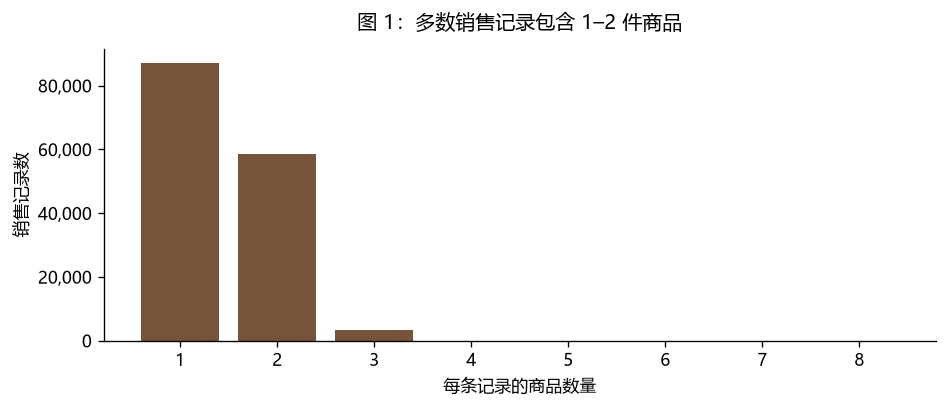

In [7]:
display(df[['transaction_qty', 'unit_price', 'revenue']].describe().T)
qty_counts = df.transaction_qty.value_counts().sort_index().reindex(range(1, int(df.transaction_qty.max()) + 1), fill_value=0)
display(pd.DataFrame({'数量': qty_counts.index, '记录数': qty_counts.values,
                      '占比_%': qty_counts.values / len(df) * 100}))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(qty_counts.index, qty_counts.values, color='#78533C')
ax.set(title='图 1：多数销售记录包含 1–2 件商品', xlabel='每条记录的商品数量', ylabel='销售记录数')
ax.set_xticks(qty_counts.index)
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
fig.tight_layout()
plt.show()


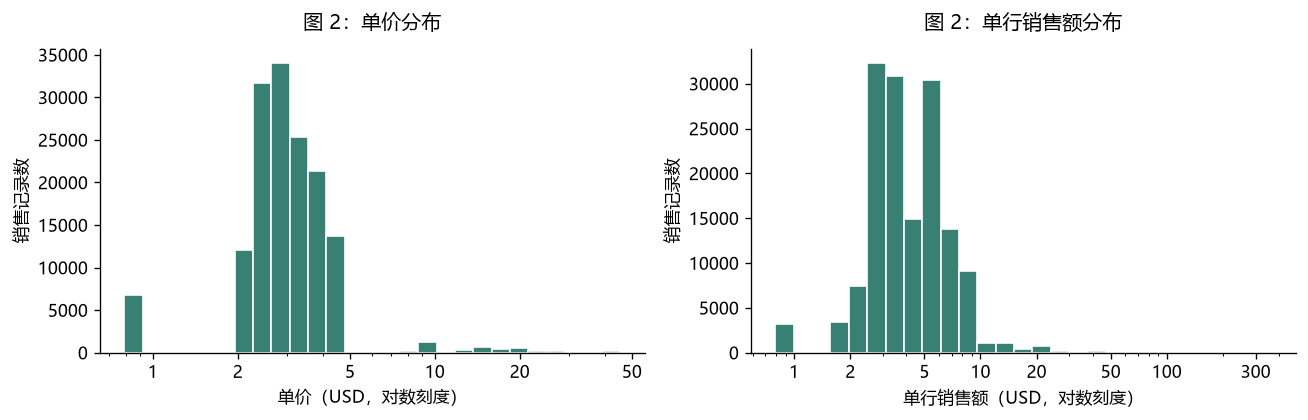

单行金额 IQR 上界：$10.50；超过上界 3,273 行，占 2.19%。
IQR 只用于定位，不自动删除。高价咖啡豆与饮料不能混用同一个异常判定阈值。


,transaction_id,transaction_date,store_location,product_category,product_detail,transaction_qty,unit_price,revenue
9310,9340,2023-01-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
9365,9395,2023-01-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
68806,68976,2023-04-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
68981,69151,2023-04-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
97979,98233,2023-05-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
98275,98529,2023-05-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
133186,133523,2023-06-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0
133337,133674,2023-06-17,Hell's Kitchen,Coffee beans,Civet Cat,8,45.0,360.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in zip(axes, ['unit_price', 'revenue'], ['单价', '单行销售额']):
    values = df[col]
    bins = np.geomspace(values.min() * .99, values.max() * 1.01, 28)
    ax.hist(values, bins=bins, color='#398074', edgecolor='white')
    ax.set_xscale('log')
    ax.set(title=f'图 2：{title}分布', xlabel=f'{title}（USD，对数刻度）', ylabel='销售记录数')
    ax.set_xticks([1, 2, 5, 10, 20, 50] if col == 'unit_price' else [1, 2, 5, 10, 20, 50, 100, 300])
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
fig.tight_layout()
plt.show()
q1, q3 = df.revenue.quantile([.25, .75])
iqr_upper = q3 + 1.5 * (q3 - q1)
large_rows = df.revenue.gt(iqr_upper)
print(f'单行金额 IQR 上界：${iqr_upper:.2f}；超过上界 {large_rows.sum():,} 行，占 {large_rows.mean():.2%}。')
print('IQR 只用于定位，不自动删除。高价咖啡豆与饮料不能混用同一个异常判定阈值。')
display(df.nlargest(8, 'revenue')[['transaction_id', 'transaction_date', 'store_location',
        'product_category', 'product_detail', 'transaction_qty', 'unit_price', 'revenue']])


**怎么读：**最大单行金额是 8 × 45 = 360 USD，对应 Civet Cat 咖啡豆，算术关系成立。因此保留，并标注“待业务核查”，不把它直接当作录入错误或典型咖啡饮品订单。直方图保留全部数据，用对数横轴展示长尾。


## 7. 时间趋势：销售额变化是数量还是单行金额推动的？

不同月份天数不同，必须同时看月合计和日均。完整月份才计算月环比；这里原始时间范围覆盖六个完整自然月。没有去年同期数据，不能做同比，也不能把半年趋势当作全年季节性。


,month,records,units,observed_days,revenue_usd,daily_revenue_usd,daily_records,avg_row_value_usd,revenue_mom_pct,daily_revenue_mom_pct
0,2023-01,17314,24870,31,81677.74,2634.77,558.52,4.72,NaN,NaN
1,2023-02,16359,23550,28,76145.19,2719.47,584.25,4.65,-6.77,3.21
2,2023-03,21229,30406,31,98834.68,3188.22,684.81,4.66,29.80,17.24
3,2023-04,25335,36469,30,118941.08,3964.70,844.50,4.69,20.34,24.35
4,2023-05,33527,48233,31,156727.76,5055.73,1081.52,4.67,31.77,27.52
5,2023-06,35352,50942,30,166485.88,5549.53,1178.40,4.71,6.23,9.77


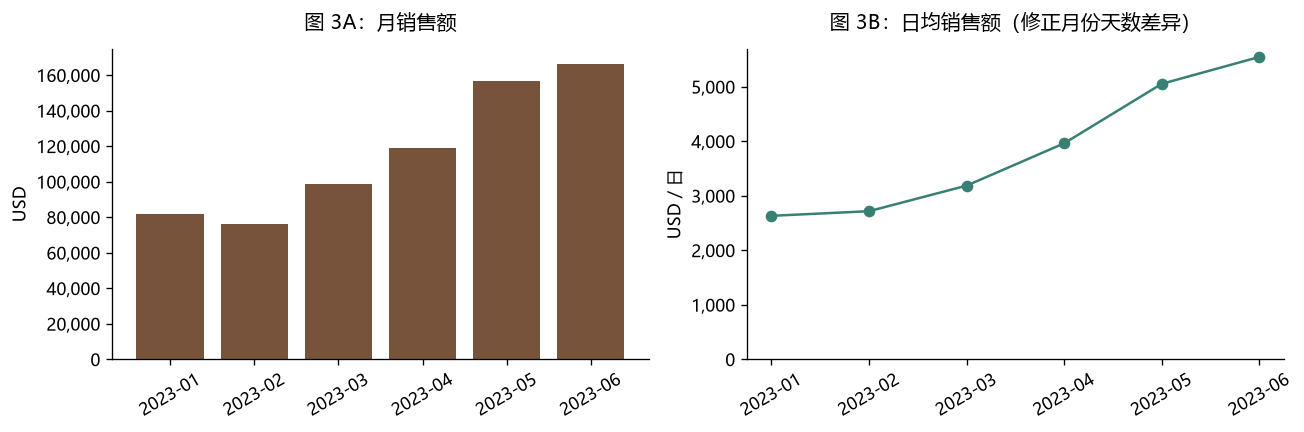

2 月月销售额环比 -6.77%，但日均销售额环比 +3.21%。
6 月相对 1 月：月销售额 +103.8%；销售记录数 +104.2%；平均单行金额 -0.17%。
销售额增长主要伴随记录数增长，单行金额基本稳定。这是描述分解，不是促销或任何其他因素的因果证据。


In [9]:
monthly = df.groupby('month').agg(
    revenue_cents=('revenue_cents', 'sum'), records=('transaction_id', 'size'),
    units=('transaction_qty', 'sum'), observed_days=('transaction_date', 'nunique')
)
monthly['revenue_usd'] = monthly.revenue_cents / 100
monthly['daily_revenue_usd'] = monthly.revenue_usd / monthly.observed_days
monthly['daily_records'] = monthly.records / monthly.observed_days
monthly['avg_row_value_usd'] = monthly.revenue_usd / monthly.records
monthly['revenue_mom_pct'] = monthly.revenue_usd.pct_change() * 100
monthly['daily_revenue_mom_pct'] = monthly.daily_revenue_usd.pct_change() * 100
display(monthly.drop(columns='revenue_cents').reset_index())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar(monthly.index, monthly.revenue_usd, color='#78533C')
axes[0].set(title='图 3A：月销售额', ylabel='USD')
axes[1].plot(monthly.index, monthly.daily_revenue_usd, marker='o', color='#398074')
axes[1].set(title='图 3B：日均销售额（修正月份天数差异）', ylabel='USD / 日')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()
print(f'2 月月销售额环比 {monthly.loc["2023-02", "revenue_mom_pct"]:+.2f}%，但日均销售额环比 {monthly.loc["2023-02", "daily_revenue_mom_pct"]:+.2f}%。')
print(f'6 月相对 1 月：月销售额 {monthly.revenue_usd.iloc[-1] / monthly.revenue_usd.iloc[0] - 1:+.1%}；销售记录数 {monthly.records.iloc[-1] / monthly.records.iloc[0] - 1:+.1%}；平均单行金额 {monthly.avg_row_value_usd.iloc[-1] / monthly.avg_row_value_usd.iloc[0] - 1:+.2%}。')
print('销售额增长主要伴随记录数增长，单行金额基本稳定。这是描述分解，不是促销或任何其他因素的因果证据。')


## 8. 门店对比：差距有多大？

三家门店覆盖相同的 181 个日期，先用同一时间窗口比较。销售额领先不等于效率更高：没有营业面积、人员工时、租金、客流或完整营业时段数据。


In [10]:
store_summary = df.groupby('store_location').agg(
    revenue_cents=('revenue_cents', 'sum'), records=('transaction_id', 'size'),
    units=('transaction_qty', 'sum'), days=('transaction_date', 'nunique')
)
store_summary['revenue_usd'] = store_summary.revenue_cents / 100
store_summary['revenue_share_pct'] = store_summary.revenue_usd / total_revenue * 100
store_summary['daily_revenue_usd'] = store_summary.revenue_usd / store_summary.days
store_summary['avg_row_value_usd'] = store_summary.revenue_usd / store_summary.records
display(store_summary.drop(columns='revenue_cents').sort_values('revenue_usd', ascending=False).reset_index())
print(f'最高与最低门店销售额差距：{store_summary.revenue_usd.max() / store_summary.revenue_usd.min() - 1:.2%}。')
print('差距较小，仅凭收入排名不足以提出关店、扩店或门店效率结论。')


,store_location,records,units,days,revenue_usd,revenue_share_pct,daily_revenue_usd,avg_row_value_usd
0,Hell's Kitchen,50735,71737,181,236511.17,33.84,1306.69,4.66
1,Astoria,50599,70991,181,232243.91,33.23,1283.12,4.59
2,Lower Manhattan,47782,71742,181,230057.25,32.92,1271.03,4.81


最高与最低门店销售额差距：2.81%。
差距较小，仅凭收入排名不足以提出关店、扩店或门店效率结论。


## 9. 商品结构与价格变化

销量衡量备货需求，销售额衡量收入贡献。价格高的商品即使销量较少也可能贡献较多收入。缺少成本时不做“最赚钱商品”排名。


,product_category,records,units,revenue_usd,revenue_share_pct
0,Coffee,58416,89250,269952.45,38.63
1,Tea,45449,69737,196405.95,28.11
2,Bakery,22796,23214,82315.64,11.78
3,Drinking Chocolate,11468,17457,72416.00,10.36
4,Coffee beans,1753,1828,40085.25,5.74
5,Branded,747,776,13607.00,1.95
6,Loose Tea,1210,1210,11213.60,1.60
7,Flavours,6790,10511,8408.80,1.20
8,Packaged Chocolate,487,487,4407.64,0.63


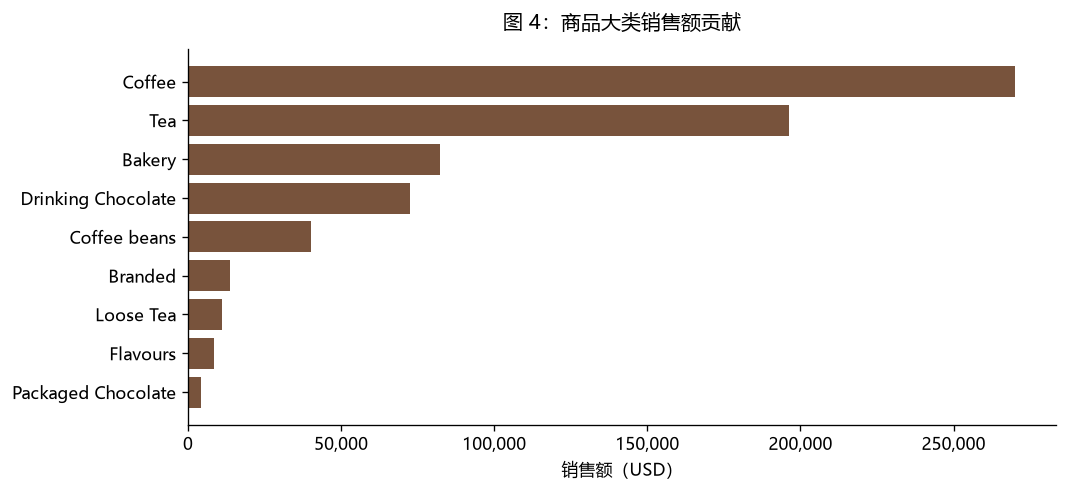

Coffee + Tea 占总销售额 66.74%。
销售额最高的 10 个商品（EDA 明细，不意味着必须放进看板）：


,product_id,product_detail,product_category,units,records,revenue_usd
60,61,Sustainably Grown Organic Lg,Drinking Chocolate,4453,2961,21151.75
58,59,Dark chocolate Lg,Drinking Chocolate,4668,3029,21006.00
38,39,Latte Rg,Coffee,4497,2896,19112.25
40,41,Cappuccino Lg,Coffee,4151,2772,17641.75
54,55,Morning Sunrise Chai Lg,Tea,4346,2830,17384.00
37,38,Latte,Coffee,4602,2990,17257.50
35,36,Jamaican Coffee River Lg,Coffee,4395,2911,16481.25
59,60,Sustainably Grown Organic Rg,Drinking Chocolate,4329,2842,16233.75
39,40,Cappuccino,Coffee,4266,2793,15997.50
26,27,Brazilian Lg,Coffee,4317,2771,15109.50


In [11]:
category_summary = df.groupby('product_category').agg(
    revenue_cents=('revenue_cents', 'sum'), records=('transaction_id', 'size'), units=('transaction_qty', 'sum')
)
category_summary['revenue_usd'] = category_summary.revenue_cents / 100
category_summary['revenue_share_pct'] = category_summary.revenue_usd / total_revenue * 100
display(category_summary.drop(columns='revenue_cents').sort_values('revenue_usd', ascending=False).reset_index())
ordered = category_summary.sort_values('revenue_usd')
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(ordered.index, ordered.revenue_usd, color='#78533C')
ax.set(title='图 4：商品大类销售额贡献', xlabel='销售额（USD）')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
fig.tight_layout()
plt.show()
print(f'Coffee + Tea 占总销售额 {category_summary.loc[["Coffee", "Tea"], "revenue_usd"].sum() / total_revenue:.2%}。')
product_summary = df.groupby(['product_id', 'product_detail', 'product_category']).agg(
    units=('transaction_qty', 'sum'), records=('transaction_id', 'size'), revenue_cents=('revenue_cents', 'sum')
).reset_index()
product_summary['revenue_usd'] = product_summary.revenue_cents / 100
print('销售额最高的 10 个商品（EDA 明细，不意味着必须放进看板）：')
display(product_summary.drop(columns='revenue_cents').nlargest(10, 'revenue_usd'))


In [12]:
price_check = df.groupby(['product_id', 'product_detail', 'product_category']).agg(
    distinct_prices=('unit_price_cents', 'nunique'), min_price=('unit_price', 'min'),
    max_price=('unit_price', 'max'), records=('transaction_id', 'size')
).reset_index()
variable_prices = price_check.loc[price_check.distinct_prices.gt(1)].sort_values('distinct_prices', ascending=False)
print(f'{len(variable_prices)} 个商品出现多个单价；保留逐行实际单价，不用统一商品价覆盖。')
display(variable_prices)
print('示例：商品 ID 9 的单价分布，不能仅凭低价就假定为促销：')
display(df.loc[df.product_id.eq(9)].groupby(['product_id', 'product_detail', 'unit_price']).agg(
    records=('transaction_id', 'size'), first_date=('transaction_date', 'min'), last_date=('transaction_date', 'max')
).reset_index())


15 个商品出现多个单价；保留逐行实际单价，不用统一商品价覆盖。


,product_id,product_detail,product_category,distinct_prices,min_price,max_price,records
8,9,Organic Decaf Blend,Coffee beans,4,12.00,28.00,206
67,72,Ginger Scone,Bakery,3,2.65,4.06,2324
64,69,Hazelnut Biscotti,Bakery,2,3.25,4.06,2009
65,70,Cranberry Scone,Bakery,2,3.25,4.06,2077
66,71,Chocolate Croissant,Bakery,2,3.75,4.69,3076
68,73,Almond Croissant,Bakery,2,3.75,4.69,1903
69,74,Ginger Biscotti,Bakery,2,3.50,4.38,1811
70,75,Croissant,Bakery,2,3.50,4.38,1933
71,76,Chocolate Chip Biscotti,Bakery,2,3.50,4.38,1891
73,78,Scottish Cream Scone,Bakery,2,4.50,5.63,1952


示例：商品 ID 9 的单价分布，不能仅凭低价就假定为促销：


,product_id,product_detail,unit_price,records,first_date,last_date
0,9,Organic Decaf Blend,12.0,7,2023-01-07,2023-06-30
1,9,Organic Decaf Blend,22.5,177,2023-01-08,2023-06-26
2,9,Organic Decaf Blend,23.0,5,2023-01-30,2023-06-07
3,9,Organic Decaf Blend,28.0,17,2023-01-07,2023-06-07


## 10. 需求时段：什么时候需要准备更多饮品？

排班与备料更关心制作量，而不是收入。以下只统计需要现制的 Coffee、Tea、Drinking Chocolate，排除咖啡豆、周边商品、糖浆等，减少不同商品工序混在一起的影响。**饮品件数仍只是工作量代理**：不同饮品的制作时间不同，无法据此算出最优人数。

每家门店的每小时平均值以 181 个记录日期为分母，包含该时段无销售的日期。它表示“每个观察日期的该小时销量”，不是“每营业小时效率”。不同门店的营业时间没有独立资料，不能把没有记录的边缘时段都解释为无人购买。


NaN / 线条留空表示超出该门店的记录小时范围，不代表零需求或已确认停业。


store_location,小时,Astoria,Hell's Kitchen,Lower Manhattan
0,6,NaN,10.34,19.50
1,7,26.60,20.12,38.92
2,8,30.50,42.52,38.28
3,9,31.08,41.12,39.62
4,10,32.72,42.67,40.59
5,11,23.75,22.65,18.26
6,12,24.28,17.28,18.82
7,13,23.47,18.01,16.89
8,14,22.17,18.75,19.51
9,15,22.84,16.91,20.98


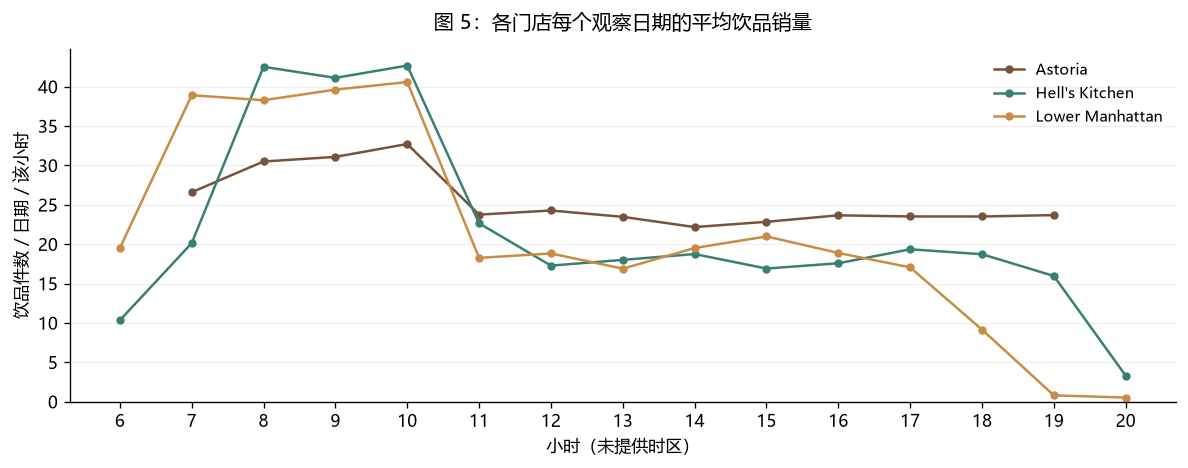

,门店,饮品销量峰值小时,8–10点饮品销量占比_%
0,Astoria,10,28.42
1,Hell's Kitchen,10,38.83
2,Lower Manhattan,10,37.29


全商品 8–10 点（08:00–10:59）销售记录占比：36.19%。


In [13]:
drink_categories = ['Coffee', 'Tea', 'Drinking Chocolate']
drinks = df.loc[df.product_category.isin(drink_categories)].copy()
observed_hours = range(int(df.hour.min()), int(df.hour.max()) + 1)
store_hour_index = pd.MultiIndex.from_product([locations, observed_hours], names=['store_location', 'hour'])
store_hour = drinks.groupby(['store_location', 'hour']).transaction_qty.sum().reindex(store_hour_index, fill_value=0)
hourly_drinks = store_hour.unstack('store_location') / len(dates)
# 无销售记录的边缘时段不推断为零需求，也不推断为已确认的营业时间。
for location in locations:
    recorded_hours = df.loc[df.store_location.eq(location), 'hour']
    outside_observed_hours = ((hourly_drinks.index < int(recorded_hours.min())) |
                              (hourly_drinks.index > int(recorded_hours.max())))
    hourly_drinks.loc[outside_observed_hours, location] = np.nan

print('NaN / 线条留空表示超出该门店的记录小时范围，不代表零需求或已确认停业。')
display(hourly_drinks.round(2).rename_axis('小时').reset_index())
fig, ax = plt.subplots(figsize=(10, 4))
for location in locations:
    ax.plot(hourly_drinks.index, hourly_drinks[location], marker='o', markersize=4, label=location)
ax.set(title='图 5：各门店每个观察日期的平均饮品销量', xlabel='小时（未提供时区）', ylabel='饮品件数 / 日期 / 该小时')
ax.set_xticks(list(observed_hours))
ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=9)
ax.grid(axis='y', alpha=.18)
fig.tight_layout()
plt.show()
peak_stats = []
for location, group in drinks.groupby('store_location'):
    hourly_units = group.groupby('hour').transaction_qty.sum()
    peak_stats.append({'门店': location, '饮品销量峰值小时': int(hourly_units.idxmax()),
                       '8–10点饮品销量占比_%': group.loc[group.hour.between(8, 10), 'transaction_qty'].sum() / group.transaction_qty.sum() * 100})
display(pd.DataFrame(peak_stats))
print(f'全商品 8–10 点（08:00–10:59）销售记录占比：{df.hour.between(8, 10).mean():.2%}。')


,weekday,calendar_days,records,daily_records,units,daily_units
0,周一,26,21643,832.42,31231,1201.19
1,周二,26,21202,815.46,30449,1171.12
2,周三,26,21310,819.62,30625,1177.88
3,周四,26,21654,832.85,31162,1198.54
4,周五,26,21701,834.65,31207,1200.27
5,周六,25,20510,820.40,29614,1184.56
6,周日,26,21096,811.38,30182,1160.85


按出现天数修正后，最忙与最闲星期的日均销售记录差距仅 2.87%。不要夸大星期差异。


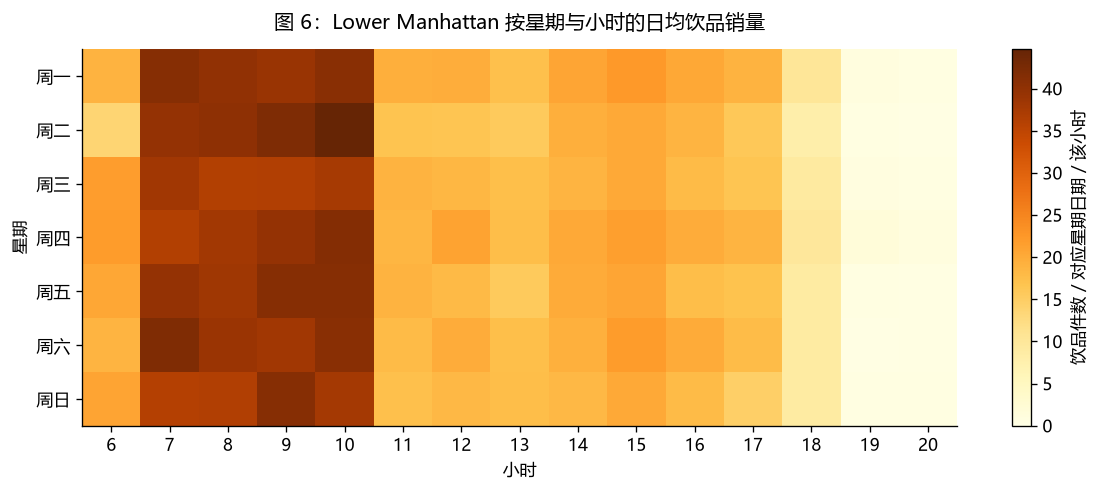

分母：周六 25 天，其余星期各 26 天；本图为全期平均，会掩盖 1–6 月的增长。正式看板应默认较近的完整 4 周。


In [14]:
calendar = pd.DataFrame({'date': dates})
calendar['weekday_num'] = calendar.date.dt.dayofweek
weekday_days = calendar.groupby('weekday_num').size().reindex(range(7))
weekday_summary = df.groupby('weekday_num').agg(records=('transaction_id', 'size'), units=('transaction_qty', 'sum'))
weekday_summary['calendar_days'] = weekday_days
weekday_summary['daily_records'] = weekday_summary.records / weekday_summary.calendar_days
weekday_summary['daily_units'] = weekday_summary.units / weekday_summary.calendar_days
weekday_summary['weekday'] = weekday_names
display(weekday_summary[['weekday', 'calendar_days', 'records', 'daily_records', 'units', 'daily_units']].reset_index(drop=True))
print(f'按出现天数修正后，最忙与最闲星期的日均销售记录差距仅 {weekday_summary.daily_records.max() / weekday_summary.daily_records.min() - 1:.2%}。不要夸大星期差异。')

SELECTED_STORE = 'Lower Manhattan'  # 讨论另一门店时只需改这里并重跑此单元格
selected_drinks = drinks.loc[drinks.store_location.eq(SELECTED_STORE)]
weekday_hour = selected_drinks.groupby(['weekday_num', 'hour']).transaction_qty.sum().unstack('hour')
weekday_hour = weekday_hour.reindex(index=range(7), columns=list(observed_hours), fill_value=0).fillna(0)
weekday_hour_mean = weekday_hour.div(weekday_days, axis=0)
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(weekday_hour_mean.values, cmap='YlOrBr', aspect='auto', vmin=0)
ax.set_xticks(range(len(observed_hours)), labels=list(observed_hours))
ax.set_yticks(range(7), labels=weekday_names)
ax.set(title=f'图 6：{SELECTED_STORE} 按星期与小时的日均饮品销量', xlabel='小时', ylabel='星期')
fig.colorbar(im, ax=ax, label='饮品件数 / 对应星期日期 / 该小时')
fig.tight_layout()
plt.show()
print('分母：周六 25 天，其余星期各 26 天；本图为全期平均，会掩盖 1–6 月的增长。正式看板应默认较近的完整 4 周。')


## 11. 清洗结果与容易误读的地方

本次结果：149,116 行全部保留；清理商品名称 Scottish Cream Scone 的 1,952 处尾部空格；解析日期时间，增加销售额、月份、星期、小时等分析字段。没有缺失值、重复 ID、非正数量或非正价格；543 个门店日均有记录。原始 CSV 保持原样，`df` 可直接用于后续讨论和看板实现。

| 问题 | 分析 / 看板应如何处理 |
|---|---|
| 398 条业务字段相同但 ID 不同的额外记录 | 保留并标注待核查，不静默去重 |
| 同时刻可能出现多个商品行 | 不用时间戳合并订单，不计算购物篮、连带率或顾客数 |
| 同一商品出现多个单价 | 按逐行实际单价计算，不能自行改为统一价格或解释为促销 |
| 高价咖啡豆导致单行金额长尾 | 保留，按类别解释；不要把大额记录当作典型饮品消费 |
| 2 月短、周六出现次数少 | 看日均并用实际日期数作分母；比较两个完整且可比的窗口 |
| 门店记录时间范围不同 | 不将边缘小时无记录自动解释为零需求或低效率 |
| 只有半年、没有成本/库存/顾客信息 | 不做全年季节性、利润、缺货预警或复购研究 |
| 数据为固定的模拟业务快照 | 明示数据期和计划刷新频率；避免用历史值表示“现在” |
| 全期平均掩盖增长 | 时段分析优先使用最近完整 4 周，并与前 4 周同星期组合比较 |

纽约业务场景可按 USD 展示，但 CSV 本身未标币种或时区；正式提交时在 README 说明币种假设，时间按原始记录保留。


In [15]:
# 结束前再验证：总量、金额、汇总及原始文件均一致。
checks = pd.Series({
    '行数保留': len(df) == len(raw),
    '销量保留': int(df.transaction_qty.sum()) == int(raw.transaction_qty.sum()),
    '逐行金额公式正确': df.revenue_cents.eq(df.transaction_qty * df.unit_price_cents).all(),
    '月销售额与总额一致': int(monthly.revenue_cents.sum()) == int(df.revenue_cents.sum()),
    '门店销售额与总额一致': int(store_summary.revenue_cents.sum()) == int(df.revenue_cents.sum()),
    '品类销售额与总额一致': int(category_summary.revenue_cents.sum()) == int(df.revenue_cents.sum()),
    '日期均解析成功': df.transaction_date.notna().all(),
    '清洗后商品无首尾空格': df.product_detail.eq(df.product_detail.str.strip()).all(),
    '原始 CSV 未改变': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256,
})
display(checks.rename_axis('核对项').reset_index(name='通过'))
assert checks.all()
print(f'销售额精确到分：{df.revenue_cents.sum():,} cents = ${total_revenue:,.2f}')


,核对项,通过
0,行数保留,True
1,销量保留,True
2,逐行金额公式正确,True
3,月销售额与总额一致,True
4,门店销售额与总额一致,True
5,品类销售额与总额一致,True
6,日期均解析成功,True
7,清洗后商品无首尾空格,True
8,原始 CSV 未改变,True


销售额精确到分：69,881,233 cents = $698,812.33


## 12. 我们讨论的研究方向（按课程适配度排序）

### 首选：门店饮品需求时段与备料安排

- **研究问题：**这家门店在什么时段需要准备更多现制饮品？最近的销量增长是否集中在原有高峰时段？
- **唯一用户：**一家门店的店长。每周排班与安排备料前查看，必要时每日营业前快速复核。
- **EDA 依据：**08:00–10:59 集中约 36.2% 的全商品销售记录；各店时段曲线不同，星期日均差异相对较小。六个月总体增长明显，使用较近窗口比全期均值更适合决策。
- **行动句：**“如果店长看到某个时段的日均现制饮品销量持续上升，就把已有班次的准备工作和备料检查前移到高峰之前，并核查该时段是否需要调整人员分配。”数据能支持需求判断，实际人数仍需工时和服务时间信息。
- **今天的替代做法（业务假设，待团队确认）：**店长导出销售流水、手工筛选时段或凭经验安排。代价可能是整理耗时或准备不足；本数据无法量化节省多少人力或收入，不能编造。
- **为什么适合看板：**同一人反复查看同一组问题，需切换近期日期并追查时段变化。一次性报告会很快失去时效。单个异常通知仍可用提醒处理，不必为每条异常增加一张图。

**建议页面，自上而下：**

1. 标题含团队名，一行说明“供门店店长安排近期备料与班次准备”。
2. 最多三个 KPI：筛选期间销售额、现制饮品销量、销售记录数。第三项是工作量线索，不能标为顾客数；可在指标旁比较前一个同长度完整周期。
3. 图一：所选门店的每日销售额趋势，用于确认是否有持续变化。
4. 图二：所选门店的星期 × 小时日均现制饮品销量，用于定位安排准备工作的时段；分母为筛选期内各星期实际日期数。
5. 仅保留门店、日期范围两个筛选。默认单个门店、最近完整 4 周；当前静态数据可用 2023-06-03 至 2023-06-30。
6. 底部放数据口径及“数据：2023-01-01 至 2023-06-30，Kaggle 固定快照；生产环境拟每日闭店后刷新”。明细仅在店长确有核查需要时展开。

**刻意不展示的两项：**商品销量 Top 10（对时段准备的主问题没有直接帮助，可留作分析）；星期销售占比饼图（全期占比不能显示近期变动，且星期总量受日期数影响）。

**刷新与查看：**拟每日闭店后导入销售流水，营业前数据可用；店长每周编排下一周时集中复核。无需秒级刷新，因为这里支持的是下一日准备和每周安排。跟踪“某高峰小时在最近完整 4 周的日均饮品销量相对前 4 周”的变化。持续两次周度检查高于 20% 可作为**初始讨论阈值**，触发准备安排核查；20% 未经业务校准，不声称是统计显著或最优阈值。陈旧一周的数据可能忽视增长并导致准备不足，但数据不足以估计金额损失。

### 备选二：商品组合与收入贡献

研究不同商品的销量和销售额贡献是否随月份变化，帮助店长安排重点商品的备货优先级。Coffee + Tea 占约 66.7% 销售额，适合聚焦主营饮品。限制是没有库存、报损或成本，只能讨论销售需求与收入，不能做自动补货或利润优化。如果选此方向，正式看板改用趋势图和商品贡献条形图，不把它们叠加到首选方案。

### 备选三：增长分解与门店经营复核

研究销售额变动来自记录数、每条记录件数、还是实际价格/商品组合。6 月相对 1 月销售额约增长 103.8%，记录数约增长 104.2%，平均单行金额变化约 −0.17%。三店累计销售额差距约 2.81%，不适合夸大排名。这个方向适合区域运营经理，但对课堂作业需要特别写清“复核哪家店、之后采取什么行动”，否则容易只做成展示报表。

**下一轮讨论建议：**先看图 3（月总额与日均）、图 5（门店饮品时段）、图 6（单店热力图），判断首选方向是否与你们想讲的业务故事一致。再决定看板元素，最后写 Streamlit。
